In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.multivariate.factor import Factor
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr
from sklearn.cluster import AgglomerativeClustering
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

In [2]:
df = pd.read_excel("simon.xlsx")
df = df.set_index("Регионы")
df = df[df.columns[:6]]
df.head()

,"Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной горячим водоснабжением, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной отоплением, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной водоотведением (канализацией), в общей площади всего жилищного фонда (процент, значение показателя за год)",Количество построенных квартир на 1000 чел. (значение показателя за год),Введено в действие общей площади жилых домов на 1000 чел. (тысяча квадратных метров общей площади)
Регионы,,,,,,
Белгородская область,90.08,80.98,99.64,84.90,5.875466,0.551034
Брянская область,83.72,70.86,92.97,77.97,4.194826,0.419396
Владимирская область,86.02,64.18,87.73,78.57,9.126813,0.886967
Воронежская область,85.67,79.02,90.14,82.40,10.789691,0.837769
Ивановская область,74.38,65.49,85.26,72.02,3.751278,0.426791


In [3]:
for column in df.columns:

    print(column)

    m = df[column].mean()
    iqr = df[column].quantile(.75) - df[column].quantile(.25)

    print("Больше")
    print(df[df[column] >= df[column].quantile(.75) + (1.5 * iqr)])
    
    print("\n")

    print("Меньше")
    print(df[df[column] <= df[column].quantile(.25) - (1.5 * iqr)])

    print("\n")

Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год)
Больше
Empty DataFrame
Columns: [Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год), Удельный вес площади жилищного фонда, оборудованной горячим водоснабжением,  в общей площади всего жилищного фонда (процент, значение показателя за год), Удельный вес площади жилищного фонда, оборудованной отоплением,  в общей площади всего жилищного фонда (процент, значение показателя за год), Удельный вес площади жилищного фонда, оборудованной водоотведением (канализацией),  в общей площади всего жилищного фонда (процент, значение показателя за год), Количество построенных квартир на 1000 чел. (значение показателя за год), Введено в действие общей площади жилых домов на 1000 чел. (тысяча квадратных метров общей площади)]
Index: []


Меньше
                          Удельн

In [4]:
std_df = df.copy()

for col in std_df.columns:
    std_df[col] = (std_df[col] - std_df[col].mean()) / std_df[col].std()

std_df.head()

,"Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной горячим водоснабжением, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной отоплением, в общей площади всего жилищного фонда (процент, значение показателя за год)","Удельный вес площади жилищного фонда, оборудованной водоотведением (канализацией), в общей площади всего жилищного фонда (процент, значение показателя за год)",Количество построенных квартир на 1000 чел. (значение показателя за год),Введено в действие общей площади жилых домов на 1000 чел. (тысяча квадратных метров общей площади)
Регионы,,,,,,
Белгородская область,0.651486,0.789120,1.264248,0.632125,-0.340447,-0.182541
Брянская область,0.116519,0.064976,0.653551,0.072954,-0.769460,-0.608560
Владимирская область,0.309982,-0.413016,0.173783,0.121367,0.489517,0.904639
Воронежская область,0.280542,0.648871,0.394440,0.430404,0.913997,0.745421
Ивановская область,-0.669109,-0.319278,-0.052367,-0.407142,-0.882684,-0.584629


In [5]:
chi_square_value, p_value = calculate_bartlett_sphericity(std_df)
chi_square_value, p_value

(602.3286877349395, 1.1363739507781915e-118)

In [6]:
kmo_all, kmo_model = calculate_kmo(std_df)
kmo_model

0.6923457650425529

In [7]:
fa = Factor(std_df[std_df.columns], n_factor = 2, method = "pa")
res = fa.fit()

In [8]:
res.rotate(method = "varimax")
res.get_loadings_frame(threshold=0)

,factor 0,factor 1
"Удельный вес площади жилищного фонда, оборудованной водоотведением (канализацией), в общей площади всего жилищного фонда (процент, значение показателя за год)",0.976477,-0.143474
"Удельный вес площади жилищного фонда, оборудованной горячим водоснабжением, в общей площади всего жилищного фонда (процент, значение показателя за год)",0.951413,-0.068286
"Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год)",0.929421,-0.117098
"Удельный вес площади жилищного фонда, оборудованной отоплением, в общей площади всего жилищного фонда (процент, значение показателя за год)",0.797861,-0.012261
Количество построенных квартир на 1000 чел. (значение показателя за год),0.101396,-0.962162
Введено в действие общей площади жилых домов на 1000 чел. (тысяча квадратных метров общей площади),0.084705,-0.954481


In [9]:
ev = res.eigenvals

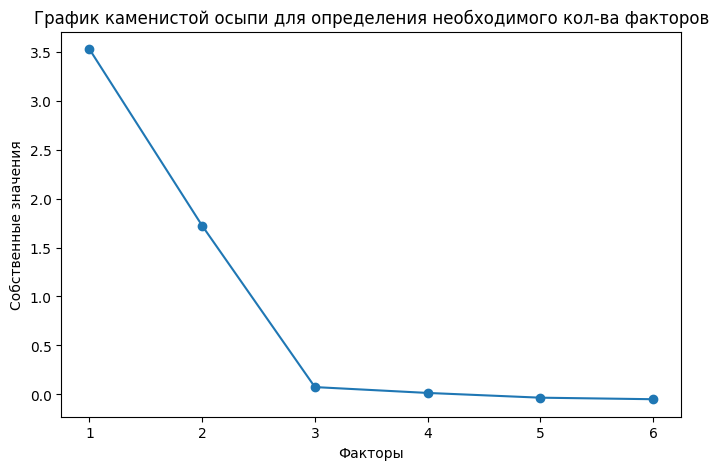

In [10]:
plt.close()

plt.figure(figsize=(8, 5))
plt.scatter(range(1,std_df.shape[1]+1),ev)
plt.plot(range(1,std_df.shape[1]+1),ev)
plt.title('График каменистой осыпи для определения необходимого кол-ва факторов')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')

plt.savefig("stones.png")

In [11]:
pd.DataFrame(res.loadings).to_excel("loadings.xlsx")

In [12]:
res.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                                                                                                                                                                                                                                                                                                                                                                                    Factor analysis results
================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================
                                                                                                                                                                                                                                                             Eigenvalues                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 Удельный вес площади жилищного фонда, оборудованной водопроводом, в общей площади всего жилищного фонда (процент, значение показателя за год) Удельный вес площади жилищного фонда, оборудованной горячим водоснабжением,  в общей площади всего жилищного фонда (процент, значение показателя за год) Удельный вес площади жилищного фонда, оборудованной отоплением,  в общей площади всего жилищного фонда (процент, значение показателя за год) Удельный вес площади жилищного фонда, оборудованной водоотведением (канализацией),  в общей площади всего жилищного фонда (процент, значение показателя за год) Количество построенных квартир на 1000 чел. (значение показателя за год) Введено в действие общей площади жилых домов на 1000 чел. (тысяча квадратных метров общей площади)
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [13]:
pces = np.dot(std_df, res.loadings)
pc1 = []
pc2 = []

for i in pces:
    print
    pc1.append(i[0])
    pc2.append(i[1])

In [14]:
data = {"regions": std_df.index, "PC1": pc1, "PC2": pc2}

integral_char = pd.DataFrame(data)
integral_char = integral_char.set_index("regions")
integral_char.head()

,PC1,PC2
regions,,
Белгородская область,2.932253,0.265429
Брянская область,0.633227,1.284643
Владимирская область,0.278585,-1.362094
Воронежская область,1.768890,-1.734651
Ивановская область,-1.504018,1.566512


In [15]:
sk_ac = AgglomerativeClustering(n_clusters=5, linkage='ward')
sk_ac_pred_res = sk_ac.fit_predict(integral_char)

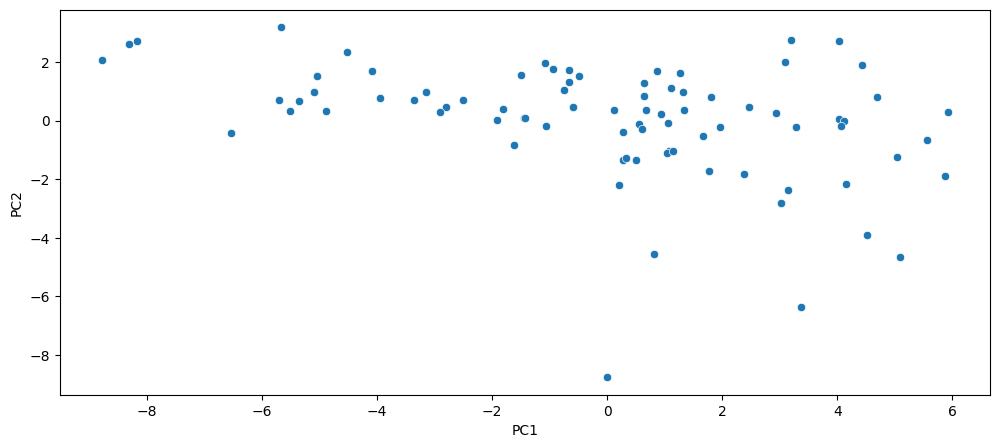

In [21]:
plt.close()
plt.figure(figsize=(12, 5))
sns.scatterplot(data = integral_char, x = "PC1", y = "PC2")
plt.savefig("scatterplot.png")

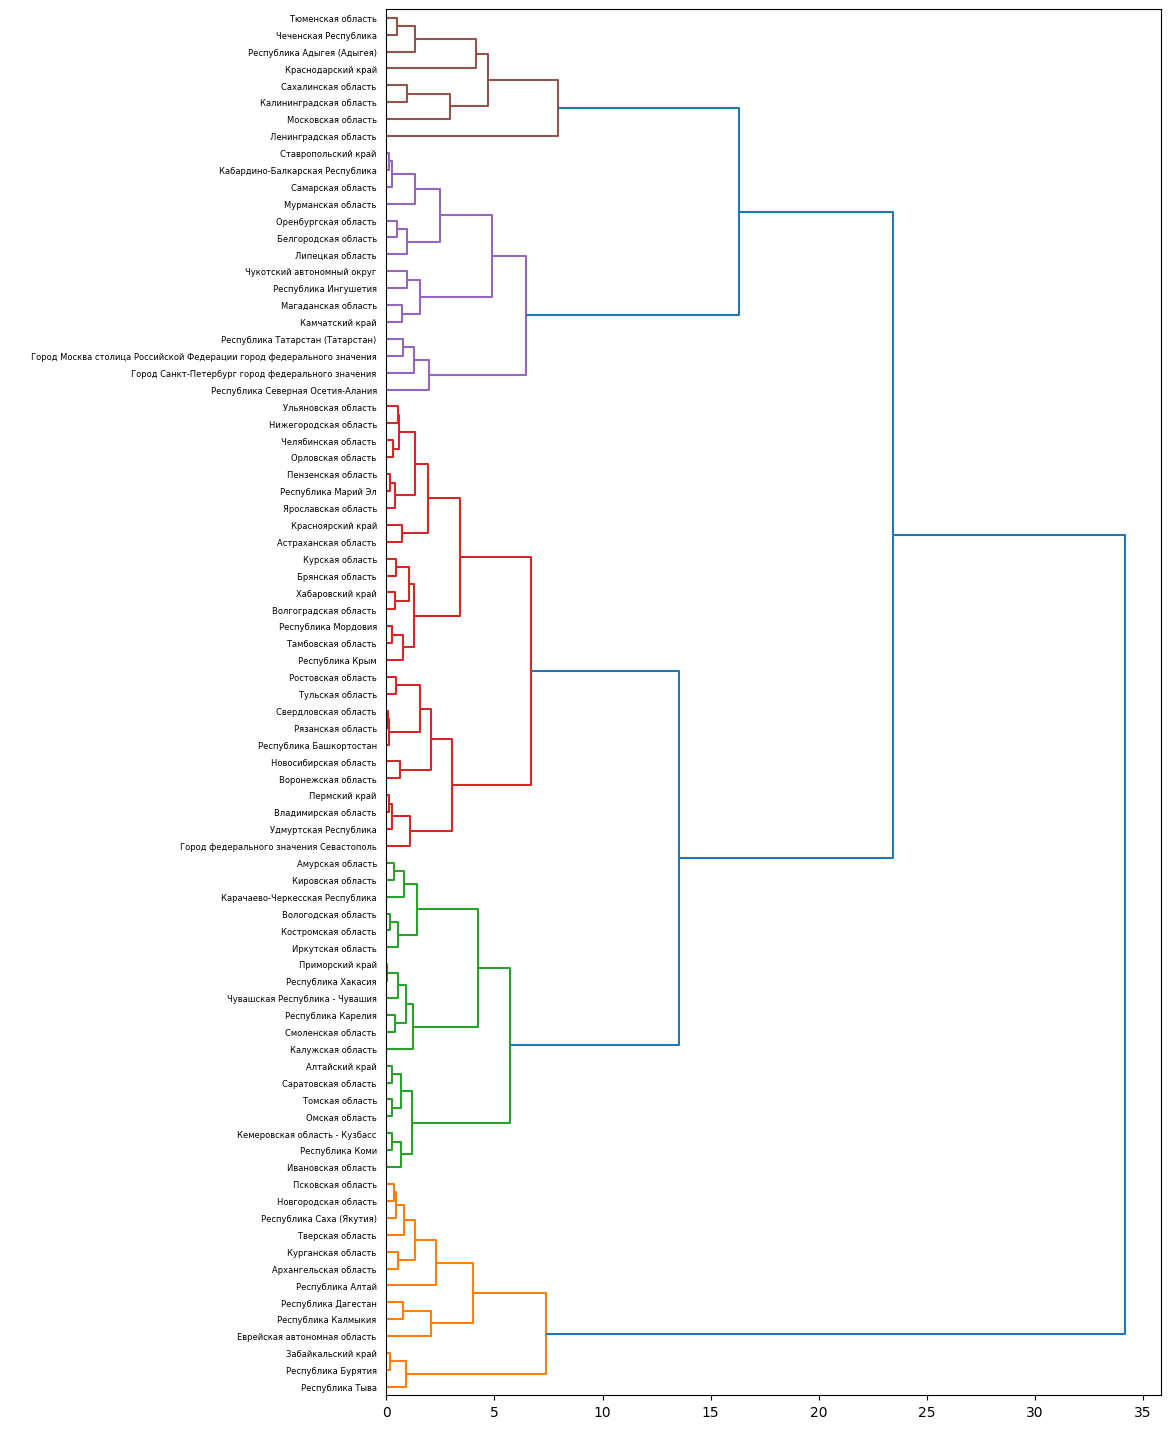

In [17]:
Z = linkage(integral_char[["PC1", "PC2"]], method='ward', metric='euclidean')

plt.close()
plt.figure(figsize=(10, 18))
dendrogram(Z, color_threshold=10, orientation="right", labels = integral_char.index)
plt.savefig("dendro.png")

In [18]:
integral_char["class"] = sk_ac_pred_res
integral_char.head()
integral_char.to_excel("clusters.xlsx")

In [19]:
integral_char.groupby("class").agg(["count", "mean"])

PC1             PC2          
      count      mean count      mean
class                                
0         8  3.012242     8 -4.444900
1        13 -5.976085    13  1.436656
2        27  0.923381    27 -0.166338
3        15  4.182702    15  0.467738
4        19 -1.793719    19  0.755671

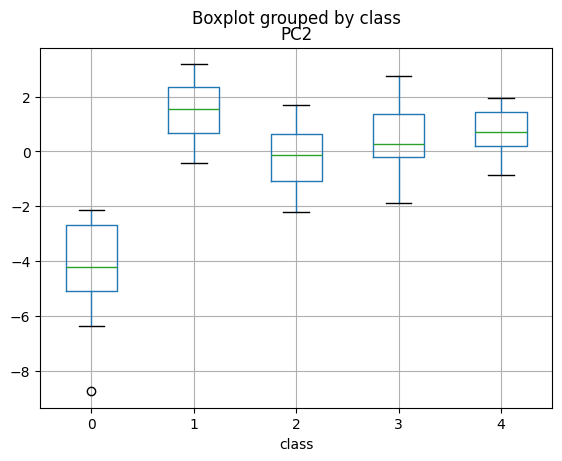

In [20]:
plt.close()
integral_char.boxplot(column="PC2", by = "class")
plt.savefig("pc2_clust_boxs.png")